# Power BI render -- notebook tests

Tries `app/powerbi_render.py` against the real Power BI service, one step at a time. Each section matches a step of the render build
(`docs/dashboard-editing.md`); later steps are added below as they are built.

Needs your own credentials (ADC) for Secret Manager. Uses the coding agent's Power BI service principal, a Member of the Agent Sandbox
workspace only. Re-run the first code cell after editing `powerbi_render.py`: it reloads the module.

In [1]:
import asyncio
import importlib
import sys

import msal

sys.path.insert(0, "..")

import app.powerbi_render as powerbi_render
from app.config import GCP_PROJECT_ID, get_secret

powerbi_render = importlib.reload(powerbi_render)


def get_coding_agent_power_bi_token() -> str:
    msal_app = msal.ConfidentialClientApplication(
        get_secret("coding-agent-power-bi-sp-client-id", GCP_PROJECT_ID),
        authority=f"https://login.microsoftonline.com/{get_secret('azure-tenant-id', GCP_PROJECT_ID)}",
        client_credential=get_secret("coding-agent-power-bi-sp-client-secret", GCP_PROJECT_ID),
    )
    result = msal_app.acquire_token_for_client(scopes=["https://analysis.windows.net/powerbi/api/.default"])
    if "access_token" not in result:
        raise RuntimeError(f"No access token: {result}")
    return result["access_token"]


def run_in_proactor_loop(coroutine_function, *args, **kwargs):
    """Playwright starts the browser as a subprocess, which the Windows notebook's own event loop cannot do: run the call on a
    proactor loop in a thread."""
    def run():
        loop = asyncio.ProactorEventLoop()
        try:
            return loop.run_until_complete(coroutine_function(*args, **kwargs))
        finally:
            loop.close()
    return asyncio.to_thread(run)


ACCESS_TOKEN = get_coding_agent_power_bi_token()
print("got a Power BI access token")

got a Power BI access token


## Step 2a: the embed config

The embed URL and an embed token for the Agent Sandbox report. The token itself is not printed.

In [ ]:
config = await powerbi_render.get_embed_config("Agent Sandbox", ACCESS_TOKEN)
print("report:", config.report_id)
print("embed url:", config.embed_url)
print("token length:", len(config.embed_token), "| expires:", config.expires_at)

### A second call reuses it

The token is reused until five minutes before it expires, so this returns the same object.

In [ ]:
again = await powerbi_render.get_embed_config("Agent Sandbox", ACCESS_TOKEN)
print("reused the cached config:", again is config)

### A target the coding agent cannot reach

The coding agent's principal is not a member of the production workspace, so this should fail with a `RenderError` that says to report it
could not render and not to retry.

In [ ]:
try:
    await powerbi_render.get_embed_config("Instacart ML Model", ACCESS_TOKEN)
except powerbi_render.RenderError as error:
    print(error)

## Step 2b: render a page

A PNG of one page of the Agent Sandbox report, from Playwright's own Chromium (`channel="chromium"`). Install it once from a
terminal: `uv run playwright install --no-shell chromium`. Power BI's grey "free trial version" bar stays in the image.

The calls go through `run_in_proactor_loop`, defined in the first cell: on Windows the notebook's event loop cannot start the browser process.

rendered the page in 36.6s, 168,524 bytes


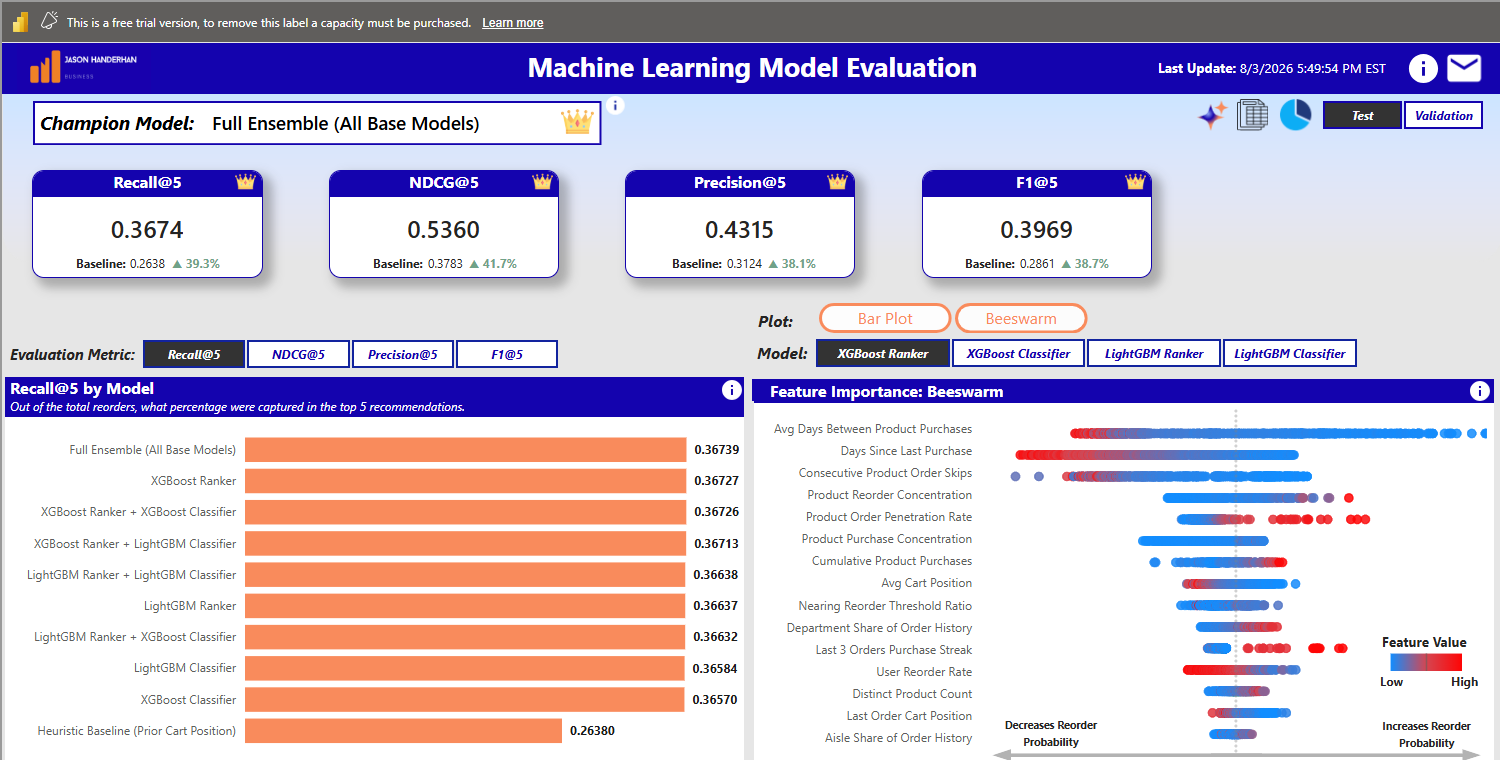

In [2]:
import time

from IPython.display import Image, display

started = time.perf_counter()
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation")
print(f"rendered the page in {time.perf_counter() - started:.1f}s, {len(png):,} bytes")
display(Image(png))

### The same page at twice the size

In [ ]:
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation", scale=2)
print(f"{len(png):,} bytes")
display(Image(png))

### An unknown page

Should fail with a `RenderError` listing the report's real page names.

In [ ]:
try:
    await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Cost")
except powerbi_render.RenderError as error:
    print(error)

## Step 2c: a bookmark

The bookmark is part of the embed, so the first render already has it applied. It is given by its id, the file name in the report's
`bookmarks/` folder. "Barplot" (`197b4914f528d7fa8856`) switches the right chart to the SHAP bars.

rendered with the Barplot bookmark in 7.1s, 113,939 bytes


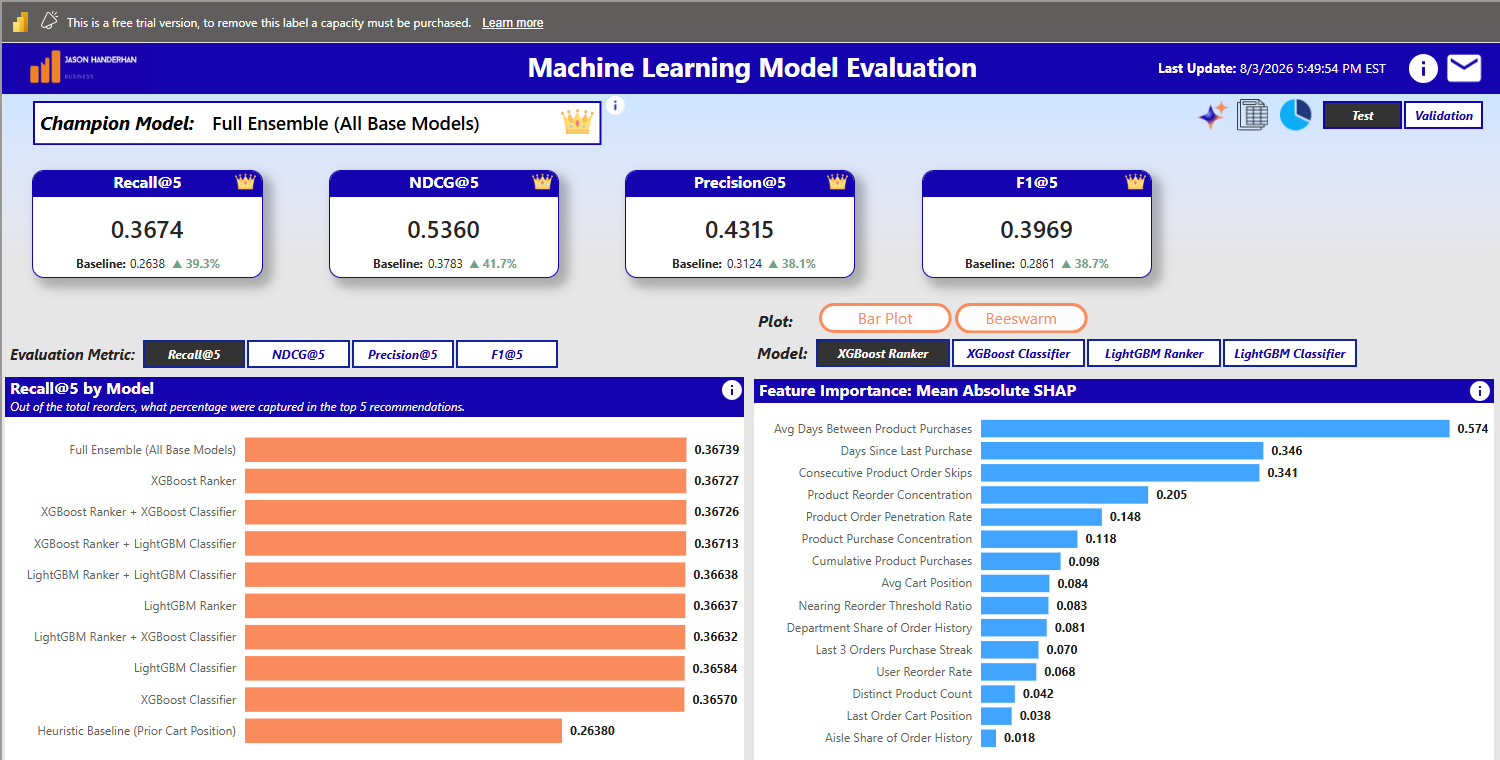

In [3]:
BARPLOT = "197b4914f528d7fa8856"

started = time.perf_counter()
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation", bookmark=BARPLOT)
print(f"rendered with the Barplot bookmark in {time.perf_counter() - started:.1f}s, {len(png):,} bytes")
display(Image(png))

### An unknown bookmark id

Should fail with a `RenderError`: Power BI's own error, then a note about where bookmark ids come from.

In [4]:
try:
    await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation", bookmark="nope")
except powerbi_render.RenderError as error:
    print(error)

The report did not render: Page.evaluate: Error: {"message":"applyBookmarkFailed","detailedMessage":{"message":"applyBookmarkFailed","detailedMessage":"Could not find bookmark","level":2},"level":3}
    at HTMLDivElement.onError (eval at evaluate (:370:30), <anonymous>:13:47)
    at e.raiseCustomEvent (<anonymous>:5:204313)
    at t.handleEvent (<anonymous>:5:198827)
    at <anonymous>:5:192316
    at Object.handler (<anonymous>:5:115948)
    at Object.handle (<anonymous>:5:116201)
    at <anonymous>:5:223504
    at Array.some (<anonymous>)
    at t.onMessageReceived (<anonymous>:5:223249)
    at t.windowMessageHandler (<anonymous>:5:220105). A bookmark id is the file name in the report's bookmarks folder.


### A bookmark on the wrong page

The Barplot bookmark belongs to "Model Evaluation". Asked for on "Financial Impact", the page wins: it renders that page and the bookmark has
no visible effect, with no error. This cell is here to show that.

In [ ]:
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Financial Impact", bookmark=BARPLOT)
print(f"{len(png):,} bytes")
display(Image(png))

## Step 3: slicers

Slicers are set by title as soon as the report has loaded, before its first render finishes, so there is one render. Each takes the values to
select; a field-parameter slicer takes its table-qualified name. Compare each picture with the same report in the Power BI service with the
same slicers set by hand, and look for faded or half-drawn visuals (the bookmark render needed a 1 second pause for that).

rendered with two slicers set in 9.1s, 156,905 bytes


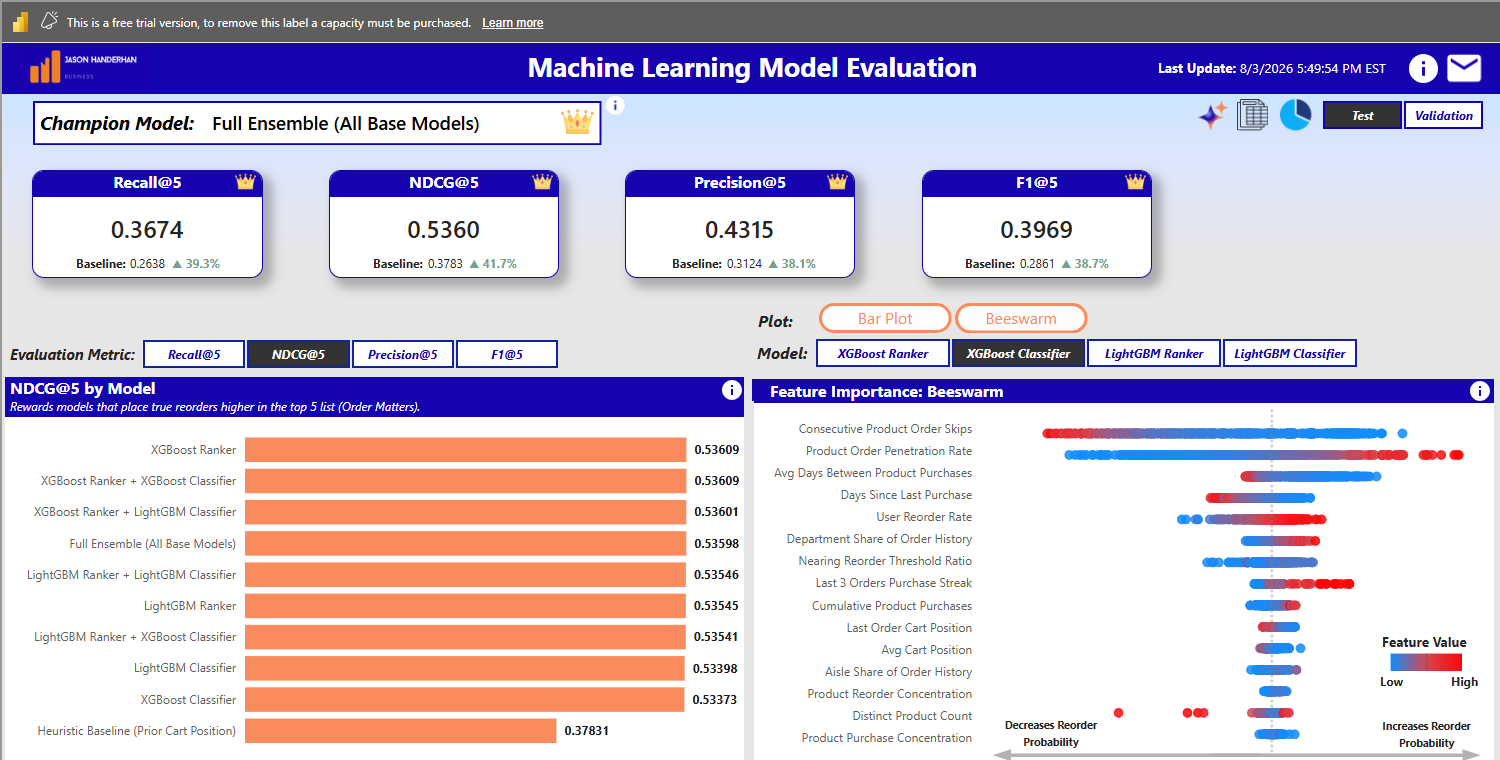

In [6]:
SLICERS = {"Model Slicer": ["XGBoost Classifier"], "Evaluation Metric Slicer": ["'_Model_Evaluation_Measures'[NDCG]"]}

started = time.perf_counter()
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation", slicers=SLICERS)
print(f"rendered with two slicers set in {time.perf_counter() - started:.1f}s, {len(png):,} bytes")
display(Image(png, width=900))

### An unknown slicer title

Should fail with a `RenderError` listing the slicer titles on the page.

In [5]:
try:
    await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation", slicers={"Nope": ["x"]})
except powerbi_render.RenderError as error:
    print(error)

No slicer titled ['Nope'] on that page. Its slicers are: ['Evaluation Metric Slicer', 'Hidden Active Page Slicer', 'Pie Chart Slicer', 'Chart Selection Hidden  Slicer', 'Model Slicer', 'Data Split Slicer'].


### A bookmark and a slicer together

The "Open Pie Chart" bookmark (`d2a2f2c7a3fe570b2021`) shows the pie chart, and the Pie Chart Slicer is set to LGBM Ranker + LGBM Classifier
(the default is All Base Models). The slicer is a field parameter, so its value is the measure's table-qualified name. The picture should
show the pie chart open with that selection, not the default.

In [ ]:
OPEN_PIE_CHART = "d2a2f2c7a3fe570b2021"
PIE_SLICER = {"Pie Chart Slicer": ["'_Model_Evaluation_Measures'[ensemble_weights_lgbm_rank_lgbm_class]"]}

started = time.perf_counter()
png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation",
                                 bookmark=OPEN_PIE_CHART, slicers=PIE_SLICER)
print(f"rendered the pie chart with its slicer set in {time.perf_counter() - started:.1f}s, {len(png):,} bytes")
display(Image(png))

### Full Chromium or the headless shell?

Renders the same page three times with each browser, taking turns so that neither benefits from running later: full Chromium
(`channel="chromium"`) and the headless shell (no channel). Needs both installed: `uv run playwright install chromium`. Compare the times,
and look in each picture for font or layout differences and faded cards. The setting is put back afterwards.

In [ ]:
BROWSERS = {"full Chromium": "chromium", "headless shell": None}

await run_in_proactor_loop(powerbi_render.get_embed_config, "Agent Sandbox", ACCESS_TOKEN)   # so no render pays for the token
original_channel = powerbi_render.BROWSER_CHANNEL
seconds = {name: [] for name in BROWSERS}
try:
    for round_number in range(1, 4):
        for name, channel in BROWSERS.items():
            powerbi_render.BROWSER_CHANNEL = channel
            started = time.perf_counter()
            png = await run_in_proactor_loop(powerbi_render.render_page, "Agent Sandbox", ACCESS_TOKEN, page="Model Evaluation")
            seconds[name].append(time.perf_counter() - started)
            print(f"round {round_number}, {name}: {seconds[name][-1]:.1f}s, {len(png):,} bytes")
            display(Image(png, width=900))
finally:
    powerbi_render.BROWSER_CHANNEL = original_channel

for name, times in seconds.items():
    print(f"{name}: average {sum(times) / len(times):.1f}s, fastest {min(times):.1f}s")